# EMQA_L3_har_fc

**Realised intraday variation of the Romanian day-ahead price and its one-day-ahead HAR forecast over the test year 2025-11-01 to 2026-10-31, the HAR model being re-estimated every day on the data available the day before: the forecasts follow the variation, not its isolated spikes.**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_har_fc/EMQA_L3_har_fc.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## HAR forecasts of intraday variation

$\ln RV_d=b_0+b_D\ln RV_{d-1}+\frac{b_W}{7}\sum_{j=1}^{7}\ln RV_{d-j}+\frac{b_M}{30}\sum_{j=1}^{30}\ln RV_{d-j}+e_d$ (Corsi, 2009), by OLS. Forecast $=\exp(\widehat{\ln RV}_d+s^2/2)$, $s^2$ = residual variance. Test year = the last 365 days to the cut-off; the model is re-estimated every day on an expanding window.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# hourly prices of Romania (15-min MTUs averaged to the hour from 1 Oct 2025), CET/CEST clock
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', usecols=['timestamp_utc', 'RO'], parse_dates=['timestamp_utc']).set_index('timestamp_utc')['RO']
HP.index = HP.index.tz_convert('Europe/Brussels')
HP = HP.dropna().loc[str(START.date()):str(END.date())]
# intraday variation RV_d = sqrt(sum_h (P_{d,h} - P_{d,h-1})^2), within the delivery day
_h = pd.DataFrame({'p': HP.values, 'day': HP.index.tz_localize(None).normalize()})
_h['dp'] = _h.groupby('day')['p'].diff()
_gh = _h.groupby('day')
RV = pd.DataFrame({'rv': np.sqrt(_gh['dp'].apply(lambda x: (x ** 2).sum(min_count=1))), 'lvl': _gh['p'].mean()}).reindex(CAL)
print('days with RV:', int(RV['rv'].notna().sum()), 'of', len(CAL))

days with RV: 2861 of 2861


In [5]:
import statsmodels.api as sm
lr = np.log(RV['rv'])
HD = pd.DataFrame({'y': lr, 'd': lr.shift(1), 'w': lr.shift(1).rolling(7).mean(), 'm': lr.shift(1).rolling(30).mean()}).dropna()
TEST0 = END - pd.Timedelta(days=364)
TDAYS = pd.date_range(TEST0, END, freq='D')
tr = HD.loc[:TEST0 - pd.Timedelta(days=1)]
HAR = sm.OLS(tr['y'], sm.add_constant(tr[['d', 'w', 'm']])).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
pred = []
for t in TDAYS:                                       # expanding window, data up to d-1
    tr = HD.loc[:t - pd.Timedelta(days=1)]
    Xt = sm.add_constant(tr[['d', 'w', 'm']]).values
    b = np.linalg.lstsq(Xt, tr['y'].values, rcond=None)[0]
    s2 = np.var(tr['y'].values - Xt @ b)
    pred.append(np.exp(np.r_[1.0, HD.loc[t, ['d', 'w', 'm']].values] @ b + 0.5 * s2))
HARF = pd.Series(pred, index=TDAYS)
act = RV['rv'].loc[TDAYS]
naive = RV['rv'].shift(1).loc[TDAYS]

### Numbers on the slide

In [6]:
for k, nm in [('d', 'bd'), ('w', 'bw'), ('m', 'bm')]:
    slide(f'HAR coefficient b_{k.upper()} (before the test year)', f'har.{nm}', HAR.params[k], 3)
    slide(f'  HAC t-statistic', f'har.{nm}_t', HAR.tvalues[k], 1)
slide('R^2', 'har.r2', HAR.rsquared, 2)
mae_h, mae_n = (HARF - act).abs().mean(), (naive - act).abs().mean()
slide('test year MAE, HAR, EUR/MWh', 'har.mae_har', mae_h, 1)
slide("test year MAE, yesterday's value, EUR/MWh", 'har.mae_naive', mae_n, 1)
slide('error reduction, %', 'har.gain', 100 * (1 - mae_h / mae_n), 1)

HAR coefficient b_D (before the test year)                 0.398   [har.bd]
  HAC t-statistic                                          16.8   [har.bd_t]
HAR coefficient b_W (before the test year)                 0.365   [har.bw]
  HAC t-statistic                                          8.4   [har.bw_t]
HAR coefficient b_M (before the test year)                 0.218   [har.bm]
  HAC t-statistic                                          6.0   [har.bm_t]
R^2                                                        0.82   [har.r2]
test year MAE, HAR, EUR/MWh                                35.6   [har.mae_har]
test year MAE, yesterday's value, EUR/MWh                  39.1   [har.mae_naive]
error reduction, %                                         9.1   [har.gain]


### Chart

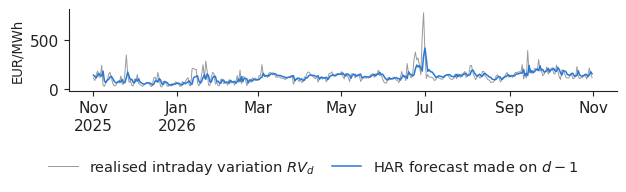

In [7]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def yfmt(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def mfmt(ax, step=1):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] +
                                               (f'\n{mdates.num2date(v).year}' if mdates.num2date(v).month == 1 or p == 0 else '')))
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ax.plot(act.index, act.values, color='#9a9a9a', lw=0.7, label='realised intraday variation $RV_d$')
ax.plot(HARF.index, HARF.values, color=PAL['RO'], lw=1.1, label='HAR forecast made on $d-1$')
ax.set_ylabel('EUR/MWh', fontsize=9.5)
mfmt(ax, 2)
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('har_fc.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()